# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/05_clasificacion_mobilenetv2.ipynb` · SHA-256 (UTF-8, saltos LF): `aca4586b0809a61de4129125fa84431a55313876bf4bb59a778d1c743e1f610d`.

Tipo: **consulta_guardada**. Fecha de ejecución/consulta: 2026-11-10T03:25:57.976945+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "figure_dpi": 55, "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2", "sistema": "Windows-10-10.0.26200-SP0"}`. Publicación: 2026-11-10T00:35:59-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [23]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/05_clasificacion_mobilenetv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. Clasificación con MobileNetV2

Tarea 2 de la consigna: clasificar cada imagen en **con paneles / sin paneles** con MobileNetV2 de Keras.

El notebook corre, uno detrás de otro, los tres modos de `EXPERIMENTOS`, con la **receta común** de los tres
clasificadores (issue #15):

| Modo | Qué se entrena |
|---|---|
| `imagenet_congelado` | extractor de ImageNet congelado, solo se entrena la cabeza |
| `imagenet_finetuning` | cabeza y después todo el extractor, con las capas de batch normalization congeladas |
| `aleatorio` | sin pre-entrenamiento, toda la red desde pesos aleatorios |

Cada modo se guarda con el formato común del equipo en `Mi unidad/PDI-TP/resultados/mobilenetv2/<modo>/`: pesos
(`modelo.keras` y checkpoints por etapa), `metricas.json`, `predicciones_val.csv` (predicción contra el real) y
`config.json`.

### Cómo correrlo sin mezclar resultados

1. **Antes de la primera corrida con la receta común**, renombrar en Drive las carpetas de modos que ya no existen,
   agregándoles `__anterior_<fecha>`: `resultados/mobilenetv2/imagenet_fine_tuning` →
   `imagenet_fine_tuning__anterior_20261027` y `imagenet_ft_completo` → `imagenet_ft_completo__anterior_20261027`.
   Las comparaciones ignoran toda carpeta con `__anterior_`. **No borrar nada.**
2. Abrir el notebook desde el botón de Colab del README (rama `main`) con GPU T4 (*Entorno de ejecución →
   Cambiar tipo de entorno*).
3. Poner `REPETIR = True` **solo la primera vez**: archiva solas las corridas viejas de `imagenet_congelado` y
   `aleatorio` (`<modo>__anterior_<fecha>`) y entrena los tres modos. *Ejecutar todas*.
4. Si Colab se corta a la mitad, volver a abrirlo con **`REPETIR = False`** y *Ejecutar todas*: los modos que ya
   quedaron completos se saltean y sigue con el resto. Con `True` volvería a archivar y entrenar lo ya hecho.
5. Para guardar también los gráficos: *Archivo → Guardar una copia en Drive*. No subir el notebook con salidas
   a GitHub.

In [ ]:
# --- Setup: correr siempre primero ---
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/PDI-TP")
    if repo.is_dir():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements-training.txt")], check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next((p for p in (Path.cwd(), Path.cwd().parent)
                 if (p / "pdi_tp" / "entorno.py").is_file()), None)
    if repo is None:
        raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde notebooks/.")
os.chdir(repo)
sys.path.insert(0, str(repo))

from pdi_tp import aumentacion, clasificacion, entorno, datos, resultados, split
rutas = entorno.preparar()


## Configuración

`BASE` es la receta común; cada experimento pisa solo los valores que cambian. No cambiar la receta acá sin
acordarlo en el issue #15: para que la comparación entre arquitecturas valga, los tres clasificadores tienen que
usar los mismos valores.

- `modo="congelado"`: `base.trainable = False`, se entrena solo la cabeza.
- `modo="fine_tuning"`: etapa 1 igual que `congelado`; etapa 2 descongela todo el extractor menos las capas de
  batch normalization y recompila con un learning rate bajo.
- `modo="completo"`: toda la red entrenable desde el inicio. Es el único modo con sentido para `pesos=None`. Baja
  el learning rate a la mitad cuando `val_loss` no mejora en 3 épocas, y el early stopping recién cuenta (y elige
  el mejor modelo) desde la época 20. Las capas de batch normalization usan momentum 0.9: MobileNetV2 trae 0.999,
  y con ~23 pasos por época sus promedios no llegan a estabilizarse, así que en val la red daba la misma
  probabilidad para todas las imágenes.

`img_size` es el tamaño con el que entra la imagen a la red. Las originales son de 256 px y entran así, sin
redimensionar. Keras tiene pesos de ImageNet para 96, 128, 160, 192 y 224; con 256 avisa y usa los de 224, que
también funcionan.

In [ ]:
REPETIR = False  # True solo la primera vez con la receta común: archiva las corridas viejas y vuelve a entrenar

MODELO = "mobilenetv2"  # carpeta en Drive: resultados/mobilenetv2/<modo>/

EXPERIMENTOS = {
    "imagenet_congelado": {"pesos": "imagenet", "modo": "congelado"},
    "imagenet_finetuning": {"pesos": "imagenet", "modo": "fine_tuning"},
    "aleatorio": {"pesos": None, "modo": "completo", "reducir_lr": True,
                  "momentum_batchnorm": 0.9, "inicio_early_stopping": 20},
}

BASE = {  # receta común de los tres clasificadores (issue #15)
    "modelo": "MobileNetV2",
    "receta": "comun_v2",
    "pesos": "imagenet",         # "imagenet" o None (pesos aleatorios)
    "modo": "fine_tuning",       # "congelado", "fine_tuning" o "completo"
    "img_size": 256,
    "batch_size": 32,
    "augmentation": True,        # aumentacion.google_maps
    "dropout": 0.3,
    "class_weight": False,       # el balance queda incorporado en PESOS_MUESTRA
    "sample_weight": "igual_masa_por_fuente_x_clase",
    # Etapa 1 (cabeza, extractor congelado): modos "congelado" y "fine_tuning"
    "epocas_cabeza": 30,
    "lr_cabeza": 1e-3,
    # Etapa 2 (todo el extractor menos batch normalization): modo "fine_tuning"
    "epocas_fine_tuning": 20,
    "lr_fine_tuning": 1e-5,
    # Modo "completo": toda la red desde el inicio
    "epocas_completo": 60,
    "lr_completo": 1e-3,
    "paciencia": 10,             # early stopping sobre val_loss
    "inicio_early_stopping": 0,  # época desde la que el early stopping cuenta y elige el mejor
    "momentum_batchnorm": None,  # None = el de MobileNetV2 (0.999)
    "reducir_lr": False,         # ReduceLROnPlateau sobre val_loss
    "reducir_lr_factor": 0.5,
    "reducir_lr_paciencia": 3,
    "umbral": 0.5,
    "semilla": 42,
}

a_correr = {}
for nombre, cambios in EXPERIMENTOS.items():
    config = {**BASE, **cambios}
    assert config["modo"] in ("congelado", "fine_tuning", "completo"), nombre
    if config["pesos"] is None and config["modo"] != "completo":
        raise ValueError(f"{nombre}: con pesos aleatorios congelar el extractor no tiene sentido, usar modo='completo'.")
    if not REPETIR and resultados.corrida_completa(resultados.ruta_corrida(rutas, MODELO, nombre)):
        print(f"Ya hecho, se saltea: {nombre}")
        continue
    a_correr[nombre] = config

print("A correr:", list(a_correr) or "nada (todos hechos; REPETIR = True para volver a entrenarlos)")

## Datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

archivos = split.cargar_split(rutas)


def cargar(imagenes):
    """Imágenes RGB uint8 (n, 256, 256, 3) y etiquetas 1 = con paneles, 0 = sin paneles."""
    X = np.stack([datos.leer_imagen(p) for p in imagenes])
    y = np.array([datos.tiene_paneles(datos.label_de(rutas, p)) for p in imagenes], dtype="float32")
    return X, y


X_train, y_train = cargar(archivos["train"])
X_val, y_val = cargar(archivos["val"])
fuentes_train = np.array([split.fuente(p.stem) for p in archivos["train"]])
PESOS_MUESTRA = clasificacion.pesos_muestra_fuente_clase(fuentes_train, y_train)
PESOS_VAL = np.ones(len(y_val), dtype="float32")

pd.DataFrame({
    "imágenes": [len(y_train), len(y_val)],
    "con paneles": [int(y_train.sum()), int(y_val.sum())],
    "sin paneles": [int((1 - y_train).sum()), int((1 - y_val).sum())],
    "% con paneles": [100 * y_train.mean(), 100 * y_val.mean()],
}, index=["train", "val"]).round(1)

El dataset está desbalanceado: la gran mayoría de las imágenes tiene paneles. Un clasificador que siempre diga
"con paneles" ya logra una accuracy alta, así que hay que mirar sobre todo **precision, recall y F1** y la matriz
de confusión. Para compensar, cada imagen de train pesa en la loss según su fuente y su clase
(`clasificacion.pesos_muestra_fuente_clase`): cada combinación fuente × clase suma el mismo peso, así el modelo no
aprende "esta fuente → esta clase". No se usa además `class_weight`.

**Augmentation** (solo en train, `aumentacion.google_maps`): rotaciones de 90° y espejados (una foto aérea no
tiene "arriba"), cambios leves de brillo y contraste, compresión JPEG y a veces un blur, para parecerse a las
capturas de Google Maps del test.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE


def aumentar(x):
    return aumentacion.google_maps(x)


def armar_ds(X, y, pesos, entrenamiento, config):
    ds = tf.data.Dataset.from_tensor_slices((X, y, pesos)).map(
        lambda x, y, peso: (tf.cast(x, tf.float32), y, peso))
    if entrenamiento:
        ds = ds.shuffle(len(X), seed=config["semilla"])
        if config["augmentation"]:
            ds = ds.map(lambda x, y, peso: (aumentar(x), y, peso), num_parallel_calls=AUTOTUNE)
    return ds.batch(config["batch_size"]).prefetch(AUTOTUNE)


# Un batch aumentado, para chequear que la augmentation tiene sentido
x_ej, y_ej, _ = next(iter(armar_ds(X_train, y_train, PESOS_MUESTRA, entrenamiento=True, config=BASE)))
fig, axs = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, x, y in zip(axs, x_ej, y_ej):
    ax.imshow(x.numpy().astype("uint8"))
    ax.set_title("con paneles" if y else "sin paneles", fontsize=9)
    ax.set_axis_off()
plt.show()

## Modelo

`MobileNetV2(include_top=False)` como extractor, y una cabeza propia: *global average pooling → dropout → dense
sigmoide*. El modelo recibe las imágenes en [0, 255] y adentro las redimensiona a `img_size` y las lleva a
[-1, 1], que es lo que espera MobileNetV2 (igual que `mobilenet_v2.preprocess_input`).

Con pesos de ImageNet la base se llama con `training=False`: así sus capas de *batch normalization* siguen usando
las estadísticas de ImageNet aunque después se descongele el extractor. Si no, en el fine-tuning se actualizarían
con batches chicos y se arruinaría lo aprendido (ver la guía de transfer learning de Keras). En el fine-tuning,
además, las capas de batch normalization quedan con `trainable = False`, para que tampoco cambien su escala y su
desplazamiento. Con pesos aleatorios
no hay estadísticas que preservar, así que la base se llama normalmente.

In [ ]:
def armar_modelo(config):
    s = config["img_size"]
    base = keras.applications.MobileNetV2(input_shape=(s, s, 3), include_top=False, weights=config["pesos"])
    if config["momentum_batchnorm"] is not None:
        for capa in base.layers:
            if isinstance(capa, keras.layers.BatchNormalization):
                capa.momentum = config["momentum_batchnorm"]

    entradas = keras.Input(shape=(256, 256, 3))
    x = keras.layers.Resizing(s, s)(entradas) if s != 256 else entradas
    x = keras.layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False) if config["pesos"] == "imagenet" else base(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(config["dropout"])(x)
    salidas = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(entradas, salidas, name=config["modelo"]), base

## Entrenamiento y evaluación

`correr_experimento` hace todo para un experimento:

1. **Entrena** por etapas. Cada vez que cambia `trainable` hay que volver a compilar, así que cada etapa compila y
   entrena. Se guarda en Drive el mejor modelo de cada etapa según `val_loss`, y el early stopping restaura esos
   pesos al terminar.
2. **Evalúa sobre val** con las métricas que pide la consigna: matriz de confusión, accuracy, precision, recall y
   F1, con la clase positiva = *con paneles*. Muestra también los errores, para entender qué le cuesta al modelo.
3. **Guarda** el modelo, las probabilidades por imagen de val (para comparar después con el detector usado como
   clasificador sobre las mismas imágenes) y el JSON del experimento.

In [ ]:
import time

from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)


def entrenar(nombre, model, etapa, lr, epocas, train_ds, val_ds, config):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"), keras.metrics.AUC(name="auc")],
    )
    entrenables = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"--- Etapa {etapa}: lr={lr}, {entrenables:,} parámetros entrenables ---")
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=config["paciencia"], restore_best_weights=True,
                                      start_from_epoch=config["inicio_early_stopping"]),
        keras.callbacks.ModelCheckpoint(str(resultados.ruta_corrida(rutas, MODELO, nombre) / f"checkpoint_{etapa}.keras"),
                                        monitor="val_loss", save_best_only=True),
    ]
    if config["reducir_lr"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=config["reducir_lr_factor"],
                                                           patience=config["reducir_lr_paciencia"], verbose=1))
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epocas,
                     callbacks=callbacks, verbose=2)
    return etapa, hist.history


def graficar_historial(nombre, historiales):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    total = sum(len(h["loss"]) for _, h in historiales)
    for ax, metrica in zip(axs, ["loss", "accuracy", "recall"]):
        inicio = 0
        for etapa, h in historiales:
            epocas = range(inicio + 1, inicio + len(h[metrica]) + 1)
            ax.plot(epocas, h[metrica], label=f"train ({etapa})")
            ax.plot(epocas, h[f"val_{metrica}"], "--", label=f"val ({etapa})")
            inicio += len(h[metrica])
            if inicio < total:
                ax.axvline(inicio + 0.5, color="gray", lw=0.8)
        ax.set_title(metrica)
        ax.set_xlabel("época")
    axs[0].legend(fontsize=8)
    fig.suptitle(nombre)
    plt.tight_layout()
    plt.show()


def evaluar(nombre, model, val_ds, config):
    prob_val = model.predict(val_ds, verbose=0).ravel()
    pred_val = (prob_val >= config["umbral"]).astype(int)
    y_true = y_val.astype(int)

    metricas = {
        "accuracy": accuracy_score(y_true, pred_val),
        "precision": precision_score(y_true, pred_val, zero_division=0),
        "recall": recall_score(y_true, pred_val, zero_division=0),
        "f1": f1_score(y_true, pred_val, zero_division=0),
        "recall_sin_paneles": recall_score(y_true, pred_val, pos_label=0, zero_division=0),
        "f1_macro": f1_score(y_true, pred_val, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred_val),
        "auc": roc_auc_score(y_true, prob_val),
        "accuracy_siempre_con_paneles": float(y_true.mean()),  # referencia: clasificador trivial
        "matriz_confusion": confusion_matrix(y_true, pred_val).tolist(),  # filas = real [sin, con]
    }
    print(classification_report(y_true, pred_val, target_names=["sin paneles", "con paneles"], digits=3,
                                zero_division=0))
    print({k: round(v, 4) for k, v in metricas.items() if isinstance(v, float)})

    ConfusionMatrixDisplay.from_predictions(y_true, pred_val, display_labels=["sin paneles", "con paneles"],
                                            cmap="Blues")
    plt.title(nombre)
    plt.show()

    predicciones = pd.DataFrame({
        "archivo": [p.name for p in archivos["val"]],
        "real": y_true,
        "prob_con_paneles": prob_val,
        "pred": pred_val,
    })
    return metricas, predicciones


def mostrar_errores(predicciones):
    errores = predicciones[predicciones["real"] != predicciones["pred"]]
    print(f"{len(errores)} errores de {len(predicciones)}")
    n = min(len(errores), 16)
    if not n:
        return
    fig, axs = plt.subplots(2, 8, figsize=(18, 5))
    for ax in axs.ravel():
        ax.set_axis_off()
    for ax, (i, fila) in zip(axs.ravel(), errores.head(n).iterrows()):
        datos.dibujar_cajas(ax, rutas, archivos["val"][i])
        real = "con" if fila["real"] else "sin"
        ax.set_title(f"real: {real} | p={fila['prob_con_paneles']:.2f}", fontsize=8)
    plt.tight_layout()
    plt.show()


def correr_experimento(nombre, config):
    carpeta = resultados.carpeta_corrida(rutas, MODELO, nombre, reiniciar=REPETIR)
    keras.backend.clear_session()
    keras.utils.set_random_seed(config["semilla"])
    train_ds = armar_ds(X_train, y_train, PESOS_MUESTRA, entrenamiento=True, config=config)
    val_ds = armar_ds(X_val, y_val, PESOS_VAL, entrenamiento=False, config=config)  # sin mezclar: orden de archivos["val"]
    model, base = armar_modelo(config)

    inicio = time.perf_counter()
    historiales = []
    if config["modo"] in ("congelado", "fine_tuning"):
        base.trainable = False
        historiales.append(entrenar(nombre, model, "cabeza", config["lr_cabeza"], config["epocas_cabeza"],
                                    train_ds, val_ds, config))
    if config["modo"] == "fine_tuning":
        base.trainable = True
        for capa in base.layers:
            if isinstance(capa, keras.layers.BatchNormalization):
                capa.trainable = False
        historiales.append(entrenar(nombre, model, "fine_tuning", config["lr_fine_tuning"],
                                    config["epocas_fine_tuning"], train_ds, val_ds, config))
    if config["modo"] == "completo":
        base.trainable = True
        historiales.append(entrenar(nombre, model, "completo", config["lr_completo"], config["epocas_completo"],
                                    train_ds, val_ds, config))
    segundos = time.perf_counter() - inicio
    graficar_historial(nombre, historiales)

    metricas, predicciones = evaluar(nombre, model, val_ds, config)
    metricas["epocas_por_etapa"] = {etapa: len(h["loss"]) for etapa, h in historiales}
    metricas["segundos_entrenamiento"] = round(segundos, 1)
    mostrar_errores(predicciones)

    model.save(carpeta / "modelo.keras")
    pd.concat([pd.DataFrame(h).assign(etapa=etapa) for etapa, h in historiales]).to_csv(
        carpeta / "historia.csv", index_label="epoca")
    resultados.guardar_corrida(
        rutas, carpeta, archivos=archivos["val"], probabilidad=predicciones["prob_con_paneles"],
        params=config, umbral=config["umbral"],
        metricas_extra={k: metricas[k] for k in ("epocas_por_etapa", "segundos_entrenamiento")})

## Correr los experimentos

In [ ]:
for nombre, config in a_correr.items():
    print("=" * 110)
    print(nombre, "→", EXPERIMENTOS[nombre])
    print("=" * 110)
    correr_experimento(nombre, config)

## Comparación de modos: ¿cuál es el óptimo?

Se comparan los experimentos de MobileNetV2 guardados en `resultados/mobilenetv2/` (los de ImageNet y el de pesos
aleatorios, aunque se hayan corrido en sesiones distintas o por distintas personas) sobre las mismas 162 imágenes
de val.

**Criterio: F1 macro** (promedio de la F1 de cada clase); desempata el AUC. No sirven la accuracy ni la F1 de
*con paneles*: como casi todas las imágenes tienen paneles, el clasificador trivial que siempre dice "con paneles"
saca valores altos en las dos (fila *siempre con paneles*, y línea punteada en los gráficos). La F1 macro le da el
mismo peso a la clase *sin paneles*, así que un modelo que la ignora queda abajo.

Las métricas se recalculan desde la matriz de confusión guardada en `metricas.json`.

In [ ]:
def metricas_desde_matriz(matriz):
    (tn, fp), (fn, tp) = matriz  # filas = real [sin, con], columnas = predicho [sin, con]

    def div(a, b):
        return a / b if b else 0.0

    def f1(p, r):
        return div(2 * p * r, p + r)

    precision_con, recall_con = div(tp, tp + fp), div(tp, tp + fn)
    precision_sin, recall_sin = div(tn, tn + fn), div(tn, tn + fp)
    return {
        "f1_macro": (f1(precision_con, recall_con) + f1(precision_sin, recall_sin)) / 2,
        "balanced_accuracy": (recall_con + recall_sin) / 2,
        "recall_sin_paneles": recall_sin,
        "recall": recall_con,
        "precision": precision_con,
        "f1": f1(precision_con, recall_con),
        "accuracy": div(tp + tn, tp + tn + fp + fn),
    }


tabla = resultados.cargar_corridas(rutas)
propios = tabla[(tabla["modelo"] == MODELO) & tabla["completa"]]

if propios.empty:
    print("Todavía no hay experimentos de MobileNetV2 guardados en", resultados.ruta_corrida(rutas, MODELO, "x").parent)
else:
    comparacion = pd.DataFrame(
        [{**metricas_desde_matriz(f["matriz_confusion"]), "auc": f["roc_auc"],
          "pesos": f["params.pesos"], "modo": f["params.modo"]}
         for _, f in propios.iterrows()],
        index=propios["modo"],
    ).sort_values(["f1_macro", "auc"], ascending=False)

    n_pos, n_neg = int(y_val.sum()), int(len(y_val) - y_val.sum())
    trivial = {**metricas_desde_matriz([[0, n_neg], [0, n_pos]]), "auc": 0.5}

    mejor = comparacion.index[0]
    fila = comparacion.iloc[0]
    print(f"Óptimo según F1 macro: {mejor}  (pesos={fila['pesos']}, modo={fila['modo']})")
    print(f"  F1 macro {fila['f1_macro']:.3f} vs {trivial['f1_macro']:.3f} del trivial | "
          f"recall sin paneles {fila['recall_sin_paneles']:.3f} | AUC {fila['auc']:.3f}")
    if len(comparacion) > 1:
        segundo = comparacion.iloc[1]
        print(f"  Diferencia con el segundo ({comparacion.index[1]}): "
              f"{fila['f1_macro'] - segundo['f1_macro']:+.3f} de F1 macro. Con 20 imágenes 'sin paneles' en val, "
              "una sola imagen mueve el recall de esa clase en 0.05: diferencias chicas pueden ser ruido.")

    display(pd.concat([comparacion, pd.DataFrame([trivial], index=["(siempre con paneles)"])]).round(3))

In [ ]:
if not propios.empty:
    GRAFICO = {"f1_macro": "F1 macro (criterio)", "balanced_accuracy": "Balanced accuracy",
               "recall_sin_paneles": "Recall sin paneles", "auc": "AUC"}
    DESTACADO, RESTO, TINTA, TINTA_SEC = "#2a78d6", "#c9c8c2", "#0b0b0b", "#52514e"

    orden = comparacion.index[::-1]  # el mejor arriba
    fig, axs = plt.subplots(1, len(GRAFICO), figsize=(16, 0.55 * len(orden) + 1.4), sharey=True)
    for ax, (columna, titulo) in zip(axs, GRAFICO.items()):
        valores = comparacion.loc[orden, columna]
        ax.barh(range(len(orden)), valores, height=0.6,
                color=[DESTACADO if n == mejor else RESTO for n in orden])
        for y, v in enumerate(valores):
            ax.text(v + 0.015, y, f"{v:.3f}", va="center", fontsize=9, color=TINTA)
        ax.axvline(trivial[columna], color=TINTA_SEC, ls="--", lw=1)
        ax.set_xlim(0, 1.15)
        ax.set_title(titulo, loc="left", fontsize=11, color=TINTA)
        ax.tick_params(colors=TINTA_SEC, labelsize=9)
        ax.tick_params(axis="y", length=0)
        ax.grid(axis="x", color="#e5e4df", lw=0.6)
        ax.set_axisbelow(True)
        for lado in ("top", "right", "left"):
            ax.spines[lado].set_visible(False)
    axs[0].set_yticks(range(len(orden)), orden)
    axs[0].tick_params(axis="y", length=0, labelsize=10, labelcolor=TINTA)
    fig.text(0.01, 0.005, "Línea punteada: clasificador trivial que siempre dice 'con paneles'. "
             "En azul, el óptimo según F1 macro.", fontsize=9, color=TINTA_SEC)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

## Kingston: umbral y métricas solo sobre Jamaica

El test va a ser solo de Kingston, con **mayoría de imágenes sin paneles** (issue #7), y train tiene 85 % con
paneles: 0.5 no tiene por qué ser el mejor umbral para Kingston. Esta tabla mira solo las imágenes de Jamaica
de val (`kingston_*`, `kingston2_*` y `geo`) de **todas las corridas del equipo**:

- `*_05`: con umbral 0.5.
- `umbral`: el que maximiza la *balanced accuracy* (promedio del acierto de cada clase, que no depende de la
  proporción de clases). Es el que se usaría en el test.
- `*_cv`: estimación honesta de ese umbral. Elegir y medir sobre las mismas imágenes da un número optimista,
  así que se deja afuera un grupo espacial por vez, se elige el umbral con el resto y se aplica al que quedó
  afuera. `umbral_cv_min`/`umbral_cv_max` muestran cuánto cambia el umbral según el grupo.

Son solo 23 imágenes (11 con paneles, 12 sin): una imagen mueve el acierto de cada clase 8 o 9 puntos. Sirve
para ver problemas grandes, no para elegir entre modelos parecidos.

**Por ahora se usa 0.5:** con estas 23 imágenes, elegir el umbral no mejoró la estimación honesta en ninguna
corrida (ver el resultado en `docs/evaluacion_jamaica.md`).

In [ ]:
from pdi_tp import umbral

jamaica = umbral.tabla_jamaica(resultados.cargar_predicciones(rutas))
if jamaica.empty:
    print("Todavía no hay corridas guardadas con imágenes de Jamaica en val.")
jamaica.round(3)

Todos los experimentos del equipo:

In [ ]:
tabla

## Consultar las corridas guardadas sin entrenar
Esta celda es independiente, no requiere GPU y abre los resultados en solo lectura. En Colab requiere haber clonado el repo y agregado el acceso directo a PDI-TP. La copia publicada ejecuta únicamente esta consulta, sin reproducir los logs originales.


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


Consulta de corridas guardadas. No se volvió a entrenar ni a predecir.
Val eligió checkpoints y se usa para reportar; Jamaica es un subconjunto de val.


,modelo,modo,fecha,completa,f1_macro,balanced_accuracy,recall,recall_sin_paneles,roc_auc,jamaica.f1_macro
3,mobilenetv2,aleatorio,2026-11-02T19:49:53,True,0.430556,0.560915,0.471831,0.65,0.574296,0.380769
4,mobilenetv2,imagenet_congelado,2026-11-02T19:41:13,True,0.705989,0.794014,0.838028,0.75,0.913028,0.651515
5,mobilenetv2,imagenet_finetuning,2026-11-02T19:45:41,True,0.810803,0.879225,0.908451,0.85,0.944718,0.868571



mobilenetv2/imagenet_congelado · fecha original: 2026-11-02T19:41:13 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json 369c0c74d163f2ad9dff14ee329b25ea13933e7e4cd423e8e9d735a033bb9960
metricas.json 54e756a6ca16bae2fcf245345fe2b250be01f274bec2748f59a065a543163c37
predicciones_val.csv a2c5e813bce7e383a1e2f817e9e0ae2a7d52d28a1a38040da841a2c111e5b43c


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.pesos,params.modo,params.img_size,...,params.epocas_completo,params.lr_completo,params.paciencia,params.inicio_early_stopping,params.momentum_batchnorm,params.reducir_lr,params.reducir_lr_factor,params.reducir_lr_paciencia,params.umbral,params.semilla
0,mobilenetv2,imagenet_congelado,2026-11-02T19:41:13,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,MobileNetV2,comun_v2,imagenet,congelado,256,...,60,0.001,10,0,None,False,0.5,3,0.5,42


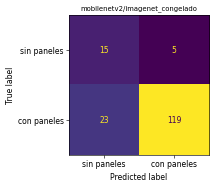

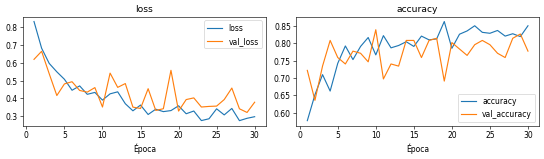


mobilenetv2/imagenet_finetuning · fecha original: 2026-11-02T19:45:41 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json 4da685d63378c7f6a29f891b0059f4ef3c8531ef605277a1b17c078e80cd7fff
metricas.json 43b05c9989f47e169062933a87df4e9d0f5bb0354b75d1aacb02f7cd7c9c96d6
predicciones_val.csv 613bc21de06be9615ed68fa4def96941adcd0bb0eb39572082cf6bc02dfed4ff


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.pesos,params.modo,params.img_size,...,params.epocas_completo,params.lr_completo,params.paciencia,params.inicio_early_stopping,params.momentum_batchnorm,params.reducir_lr,params.reducir_lr_factor,params.reducir_lr_paciencia,params.umbral,params.semilla
0,mobilenetv2,imagenet_finetuning,2026-11-02T19:45:41,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,MobileNetV2,comun_v2,imagenet,fine_tuning,256,...,60,0.001,10,0,None,False,0.5,3,0.5,42


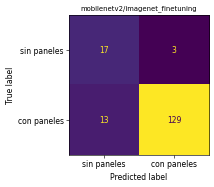

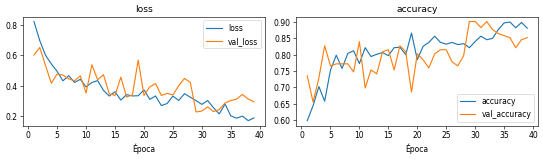


mobilenetv2/aleatorio · fecha original: 2026-11-02T19:49:53 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json a33740e6f80699ed69f2cdb5bf6e277392f15d52fea665c70fe3e12fbab6fbe0
metricas.json f8950de313588712719e72ae7fded0c3512f9de0dcbb07c7b3ab27c44cad3853
predicciones_val.csv 4c7558e6864e2265302b1cbb201a09c45897d94deb49518b3763944e1ab9c4ac


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.pesos,params.modo,params.img_size,...,params.epocas_completo,params.lr_completo,params.paciencia,params.inicio_early_stopping,params.momentum_batchnorm,params.reducir_lr,params.reducir_lr_factor,params.reducir_lr_paciencia,params.umbral,params.semilla
0,mobilenetv2,aleatorio,2026-11-02T19:49:53,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,MobileNetV2,comun_v2,None,completo,256,...,60,0.001,10,20,0.9,True,0.5,3,0.5,42


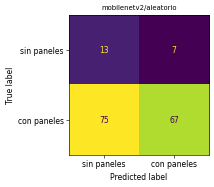

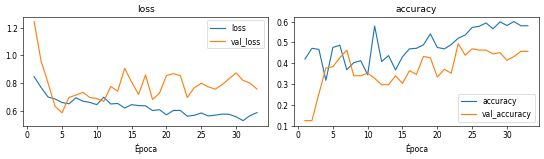

In [1]:
# Consulta independiente: ejecutar solo esta celda para mostrar resultados guardados.
# Las celdas de entrenamiento de arriba no se ejecutan en la copia publicada.
import sys
from pathlib import Path
raiz_consulta = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pdi_tp" / "lectura_entrega.py").is_file()), None)
if raiz_consulta is None:
    raise FileNotFoundError("Abrí el notebook desde el repositorio clonado.")
sys.path.insert(0, str(raiz_consulta))
from pdi_tp import lectura_entrega
lectura_entrega.mostrar_modelo("mobilenetv2")
